# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np
import gc

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget
# %matplotlib inline

INFO:2026-06-17 11:16:53,981:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-06-17 11:16:53,981 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-06-17 11:16:54,165 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
import skewerjax.utils.plotting_tools as pt
import skewerjax.utils.plotting_tools_3D_fields as pt3D_fields

import skewerjax.optical_depth.line_profile as lp
import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys

# Cosmology

In [3]:
# Create cosmology object
cosmology = Cosmology(H0=phys.H0, Omega_r_0=0.0, Omega_m_0=1.0, Omega_k_0=0.0, Omega_lambda_0=0.0)
# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time
ii_cosmology = 0

In [4]:
L_box = 110.7  # Mpc
z_box = 2.0

N_grid_skewers = 3
N_ppsk = 4096
N_v = 1024

# Lines

In [5]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "SiIII-1206"], ref_line_id = "HI-LyA") # "SiIII-1206"

# Fields

In [6]:
T0_HI = 1.5*10**4
T0_Si = T0_HI

n0_min = 1e-16
n0_max = 1e-10

def pk_template(k: jnp.ndarray, A, n, k0, k_cut):
    # P(k) = A (k/k0)^n exp[-(k/k_cut)^2]
    kk = jnp.maximum(k, 1e-12)
    return A * (kk / k0) ** n * jnp.exp(-(kk / k_cut) ** 2)
number_density_sampler = toy_samplers.number_density_sampler_gaussian_3d(
    key=jax.random.PRNGKey(0),
    pk_of_k=lambda k: pk_template(k, A=5.0, n=-2.5, k0=2.0, k_cut=50.0),
    n0_min=n0_min, n0_max=n0_max, L_box=L_box,
    grid_shape=(256, 256, 256), contrast=1.2,
)
fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_HI, T0_HI, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    }
})

# Gif generator

In [7]:
# -------------------------------------------------------- #
# ------------------- Setup & Precomputation ------------- #
# -------------------------------------------------------- #

# 1. Define the save directory
save_dir = "../SAVED_FIGURES/simulation_plots_evolution"
os.makedirs(save_dir, exist_ok=True)

# 2. Precompute the full skewer grid to extract scale factors and positions
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
points_full = jnp.reshape(points_grid_skewers, (N_grid_skewers**2, N_ppsk, 3))

# We need a temporary SkewerBundle to get the scale factors along the full skewer
skewer_bundle_full = SkewerBundle(spatial_points=points_full, cosmologies=cosmology, a0=1/(1+z_box), x0=L_box)
scale_factors_full = skewer_bundle_full.scale_factors # Shape: (N_cosmo, N_sk, N_ppsk)

# 3. Define the iterations
N_plots = 128
list_plot = np.linspace(1, N_ppsk - 1, num=N_plots, dtype=int) 

list_plot = [N_ppsk//2, N_ppsk - 1]

# --- Rotation Setup ---
azim_start = -43.0
# We will rotate the camera by exactly 180 degrees from the first to the last frame

# -------------------------------------------------------- #
# ------------------- Iteration Loop --------------------- #
# -------------------------------------------------------- #

# We use enumerate to keep track of the frame index 'k' (from 0 to N_plots - 1)
for k, ii in enumerate(list_plot):
    _N_ppsk = ii + 1
    
    # --- Calculate the dynamic azimuth for this specific frame ---
    if N_plots > 1:
        current_azim = azim_start + 180.0 * (k / (N_plots - 1)) # Linearly interpolate the azimuth from azim_start to azim_start + 180
    else:
        current_azim = azim_start
    
    # --- 1. Truncate the spatial points ---
    _points = points_full[:, 0:_N_ppsk, :]
    
    # --- 2. Get the observer's scale factor and position for this truncated skewer ---
    a0_per_skewer = float(scale_factors_full[0, 0, _N_ppsk - 1]) # The observer is at the end of the truncated skewer (index _N_ppsk - 1)
    x0_per_skewer = float(points_full[0, _N_ppsk - 1, 1])        # direction="y", so y is index 1
    
    # --- 3. Create the SkewerBundle for the truncated skewer ---
    skewer_bundle = SkewerBundle(spatial_points=_points, cosmologies=cosmology, a0=a0_per_skewer, x0=x0_per_skewer)
    
    # --- 4. Compute velocities and optical depth ---
    a_dagger = a0_per_skewer
    a_em = float(skewer_bundle.scale_factors[0, 0, 0])
    # v_max = phys.c_kms * jnp.log(a_dagger / a_em)                            # Max velocity based on truncated observer
    v_max = phys.c_kms * jnp.log(float(scale_factors_full[0, 0, -1]) / a_em) # Max velocity at the end of the box
    velocities_kms = jnp.linspace(0, v_max, N_v)
    
    tau = od.OpticalDepthCalculator(
        skewer_bundle=skewer_bundle, velocities_kms=velocities_kms,  line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
    )
    tau.compute()
    optical_depth = tau.optical_depth
    
    # --- 5. Compute other spectral coordinates ---
    a_obs = a_dagger
    
    wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(velocities_kms, line_bundle, a_dagger=a_dagger, a_obs=a_obs)
    velocities_per_line_kms = lp.reference_velocities_to_line_centered(velocities_kms, line_bundle, reference_line_idx=0)
    
    tau.wrap_to_ref_line()
    optical_depth_wrapped = tau.optical_depth
    v_min = -jnp.max(line_bundle.delta_v)
    
    # --- 6. Generate plots ---
    all_figures = pt3D_fields.generate_all_simulation_plots(
        line_bundle, skewer_bundle, fields, L_box, velocities_kms, wavelengths_per_line_A, velocities_per_line_kms,
        optical_depth, optical_depth_wrapped, a_dagger, a_em, a_obs, v_min, v_max,
        plot_normalized_velocity_units=False, plot_wrapped_velocity_units=False,
        view_elev=20.0, view_azim=current_azim, los_range=(0.0, L_box), show=False
    )
    
    # --- 7. Save figures and free memory ---
    for idx, fig in enumerate(all_figures): # idx 0-3: Cylinders, idx 4: Box, idx 5-8: Transmittance plots
        savepath = os.path.join(save_dir, f"iter{ii:04d}_fig{idx}.png")
        fig.savefig(savepath, dpi=128, bbox_inches='tight')
        plt.close(fig) # Crucial: closes the figure to prevent RAM overflow
        

    # ----------- GPU MEMORY CLEANUP -------------- #
    
    # Explicitly delete the heavy variables from this iteration. This drops the Python references to the JAX arrays and the tau object.
    del tau, optical_depth, optical_depth_wrapped, skewer_bundle, _points
    del velocities_kms, wavelengths_per_line_A, velocities_per_line_kms
    del a0_per_skewer, x0_per_skewer, a_dagger, a_em, a_obs, v_min, v_max, all_figures
    
    # Force Python garbage collection to actually free the device buffers and clear JAX's internal compilation caches to prevent memory leaks.
    gc.collect()
    jax.clear_caches()
    
    print(f"Saved plots for iteration {ii} (N_ppsk={_N_ppsk}) | Camera Azimuth: {current_azim:.1f}° | Memory Cleared.")

    
# Generate the final GIFs and clean up the PNGs
pt3D_fields.create_animated_gifs_and_cleanup(save_dir, duration_ms=500, loop=0, delete_originals=True)

2026-06-17 11:16:55,453 - INFO - Initializing SkewerBundle with 9 skewers, 4096 points per skewer
2026-06-17 11:16:55,479 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 9 skewers
2026-06-17 11:16:55,489 - INFO - All skewers set to absorption mode
2026-06-17 11:16:55,520 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-17 11:16:55,660 - INFO - Computing comoving distances along skewer direction
2026-06-17 11:16:55,763 - INFO - Computing scale factors from cosmology
2026-06-17 11:17:12,333 - INFO - Storing quadri-vectors
2026-06-17 11:17:12,369 - INFO - SkewerBundle initialization complete
2026-06-17 11:17:12,396 - INFO - Initializing SkewerBundle with 9 skewers, 2049 points per skewer
2026-06-17 11:17:12,397 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 9 skewers
2026-06-17 11:17:12,397 - INFO - All skewers set to absorption mode
2026-06-17 11:17:12,397 - INFO - Computing los_directions automatically from spatial coor

Saved plots for iteration 2048 (N_ppsk=2049) | Camera Azimuth: -43.0° | Memory Cleared.


2026-06-17 11:17:23,710 - INFO - Computing comoving distances along skewer direction
2026-06-17 11:17:23,810 - INFO - Computing scale factors from cosmology
2026-06-17 11:17:40,324 - INFO - Storing quadri-vectors
2026-06-17 11:17:40,359 - INFO - SkewerBundle initialization complete
2026-06-17 11:17:40,425 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=2, N_species=2, N_sk=9, N_ppsk=4096, N_v=1024.
2026-06-17 11:17:40,426 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 2.012 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.6%
  System RAM  : used=11.881 GB, available=113.726 GB  [███░░░░░░░░░░░░░░░░░░░░░░░░░]   9.5%
  Change      : ΔRSS=first checkpoint
2026-06-17 11:17:40,426 - INFO - [OPTICAL_DEPTH] start: ii_cosmology=0, voigt=ExoJAX
2026-06-17 11:17:40,435 - INFO - 
[OPTICAL_DEPTH][MEM] loaded quadri_vectors
  Process RSS : 2.012 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.6%
  System RAM  : used=11.881 GB, available=113.726 GB  [███░░░░░░░░░░░░░░░░░░░

Saved plots for iteration 4095 (N_ppsk=4096) | Camera Azimuth: -41.6° | Memory Cleared.
Found 4 unique figure types to animate.

🎬 Creating GIF for figure type 3 with 2 frames...
✅ Successfully saved: ../SAVED_FIGURES/simulation_plots_evolution/animation_fig3.gif
🧹 Cleaning up 2 original PNG frames to save space...
   🗑️ Deleted original frames for figure type 3.

🎬 Creating GIF for figure type 0 with 2 frames...
✅ Successfully saved: ../SAVED_FIGURES/simulation_plots_evolution/animation_fig0.gif
🧹 Cleaning up 2 original PNG frames to save space...
   🗑️ Deleted original frames for figure type 0.

🎬 Creating GIF for figure type 1 with 2 frames...
✅ Successfully saved: ../SAVED_FIGURES/simulation_plots_evolution/animation_fig1.gif
🧹 Cleaning up 2 original PNG frames to save space...
   🗑️ Deleted original frames for figure type 1.

🎬 Creating GIF for figure type 2 with 2 frames...
✅ Successfully saved: ../SAVED_FIGURES/simulation_plots_evolution/animation_fig2.gif
🧹 Cleaning up 2 origin

# Skewers & optical depth

In [8]:
# -------------------------------------------------------- #
# ---------------------- skewers ------------------------- #
# -------------------------------------------------------- #

points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
points = jnp.reshape(points_grid_skewers, (N_grid_skewers**2, N_ppsk, 3))

skewer_bundle = SkewerBundle(spatial_points=points, cosmologies=cosmology, a0=1/(1+z_box), x0=L_box)

# -------------------------------------------------------- #
# ------------------- optical depth ---------------------- #
# -------------------------------------------------------- #

a_dagger = 1 / (1 + z_box)
a_em = skewer_bundle.scale_factors[0, 0, 0]
v_max = phys.c_kms * jnp.log(a_dagger / a_em)
velocities_kms = jnp.linspace(0, v_max, N_v)
dv = np.diff(velocities_kms)[0]

tau = od.OpticalDepthCalculator(
    skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
)
tau.compute()
optical_depth = tau.optical_depth

# -------------------------------------------------------- #
# --- Other spectral coordinates, utils, and wrapping ---- #
# -------------------------------------------------------- #
a_obs = 1.0

wavelengths_per_line_A = lp.velocities_to_line_centered_wavelengths(velocities_kms, line_bundle, a_dagger=a_dagger, a_obs=a_obs)  # (N_lines, N_v)
velocities_per_line_kms = lp.reference_velocities_to_line_centered(velocities_kms, line_bundle, reference_line_idx=0)  # (N_lines, N_v)

tau.wrap_to_ref_line()
optical_depth_wrapped = tau.optical_depth

v_min = -jnp.max(line_bundle.delta_v)

2026-06-17 11:17:47,056 - INFO - Initializing SkewerBundle with 9 skewers, 4096 points per skewer
2026-06-17 11:17:47,085 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 9 skewers
2026-06-17 11:17:47,094 - INFO - All skewers set to absorption mode
2026-06-17 11:17:47,125 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-06-17 11:17:47,263 - INFO - Computing comoving distances along skewer direction
2026-06-17 11:17:47,366 - INFO - Computing scale factors from cosmology
2026-06-17 11:18:03,914 - INFO - Storing quadri-vectors
2026-06-17 11:18:03,948 - INFO - SkewerBundle initialization complete
2026-06-17 11:18:04,013 - INFO - [OPTICAL_DEPTH] initialized in compute mode: N_lines=2, N_species=2, N_sk=9, N_ppsk=4096, N_v=1024.
2026-06-17 11:18:04,014 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 2.121 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   1.7%
  System RAM  : used=12.009 GB, available=113.598 GB  [███░░░░░░░░░░░░░░░░░

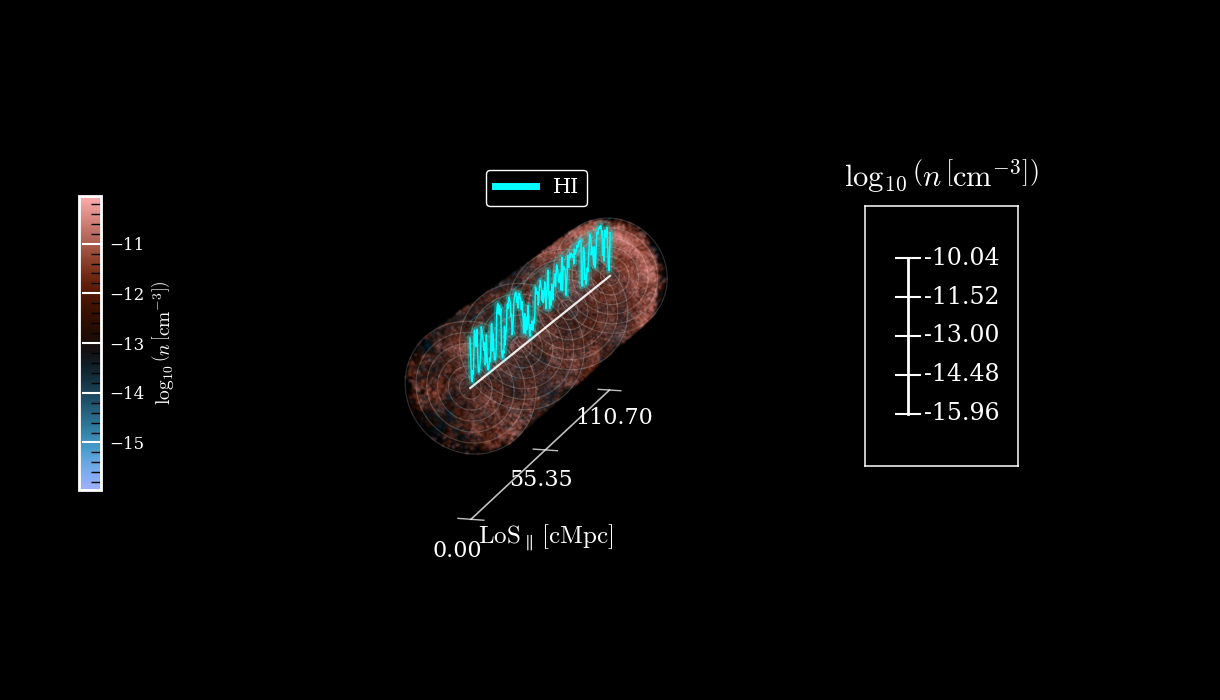

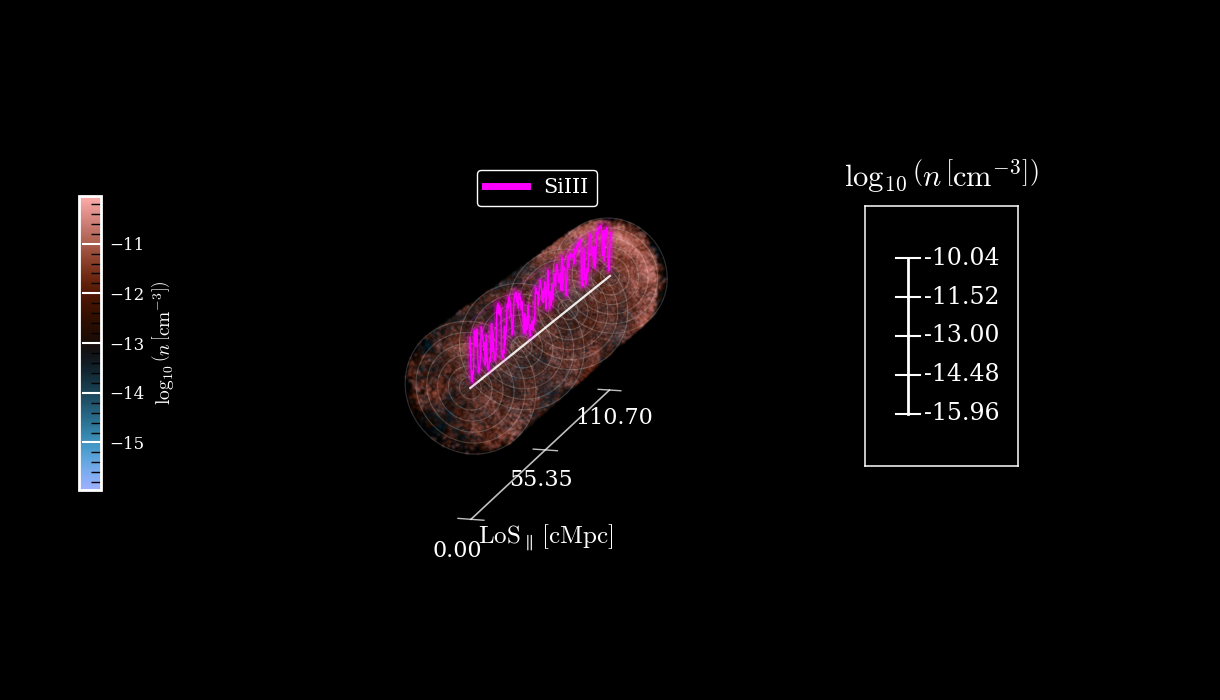

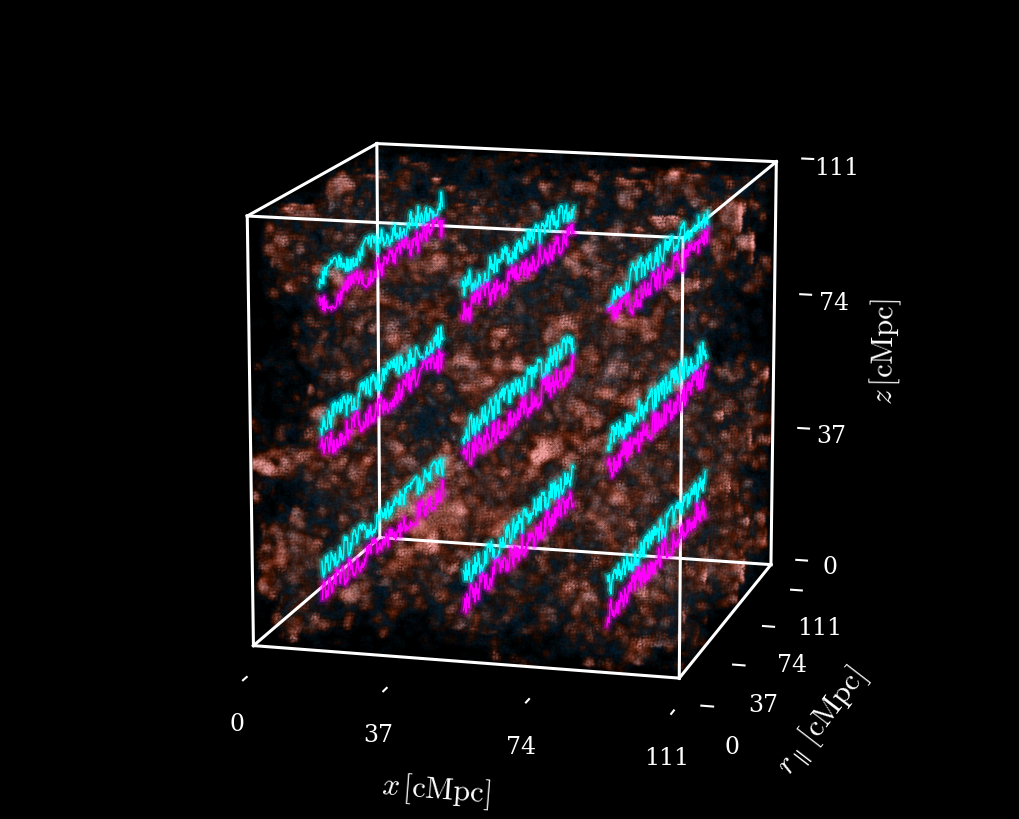

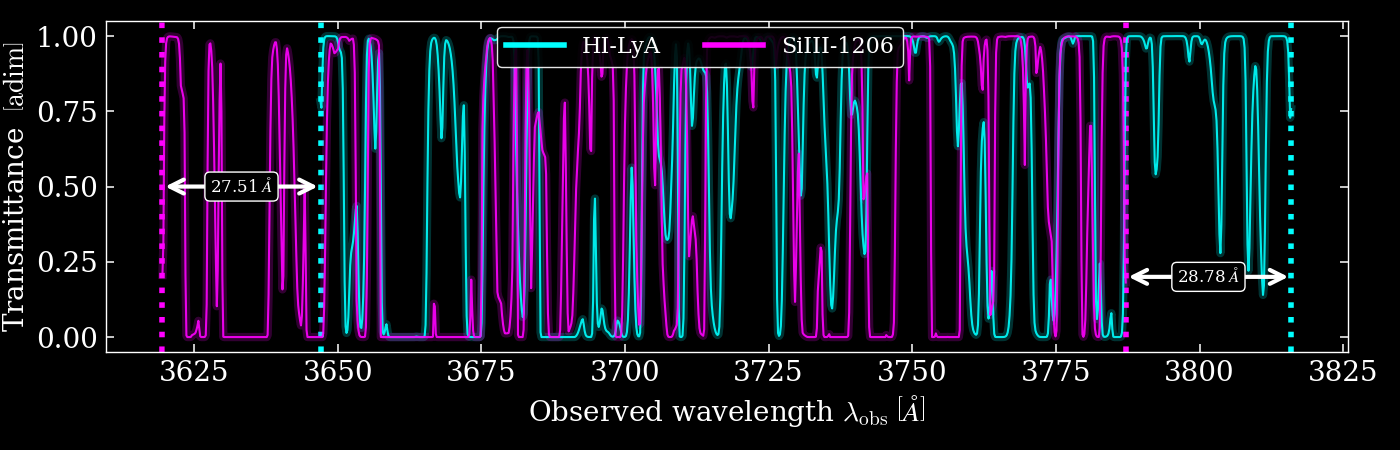

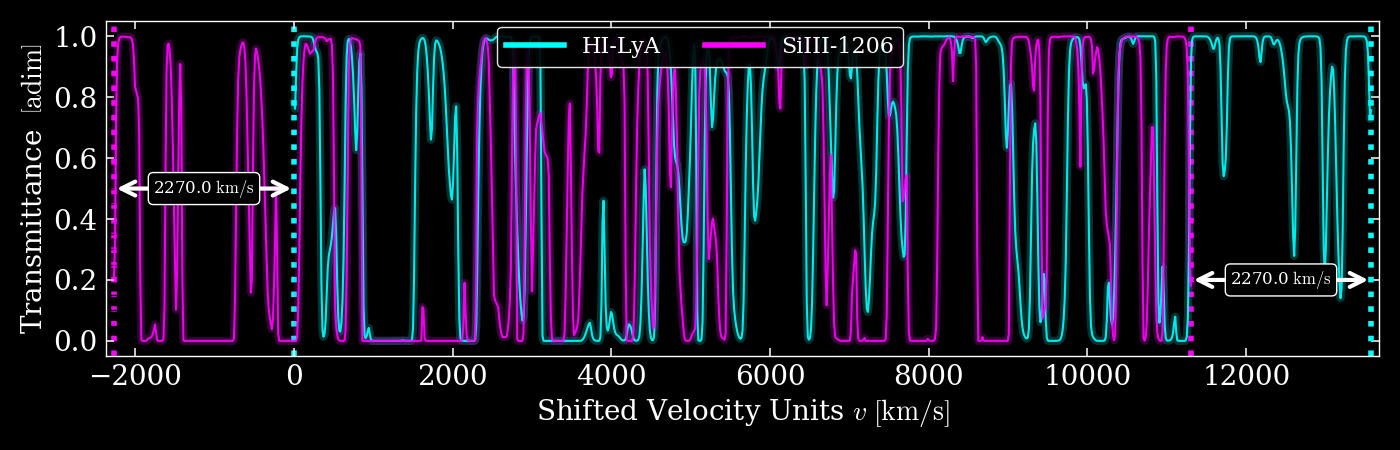

In [9]:
# ------------------------ Plots ------------------------- #
all_figures = pt3D_fields.generate_all_simulation_plots(
    line_bundle, skewer_bundle, fields, L_box, velocities_kms, wavelengths_per_line_A, velocities_per_line_kms,
    optical_depth, optical_depth_wrapped, a_dagger, a_em, a_obs, v_min, v_max, view_elev = 13.0, view_azim = -75.0,
    show=True, plot_normalized_velocity_units=False, plot_wrapped_velocity_units=False, plot_cube=True,
)
# all_figures[0].savefig("hi_cylinder.png", dpi=300, bbox_inches='tight')

In [10]:
ii_skewer = 0

colors = pt3D_fields._neon_colors(line_bundle.species_keys)
linestyles = ['-']

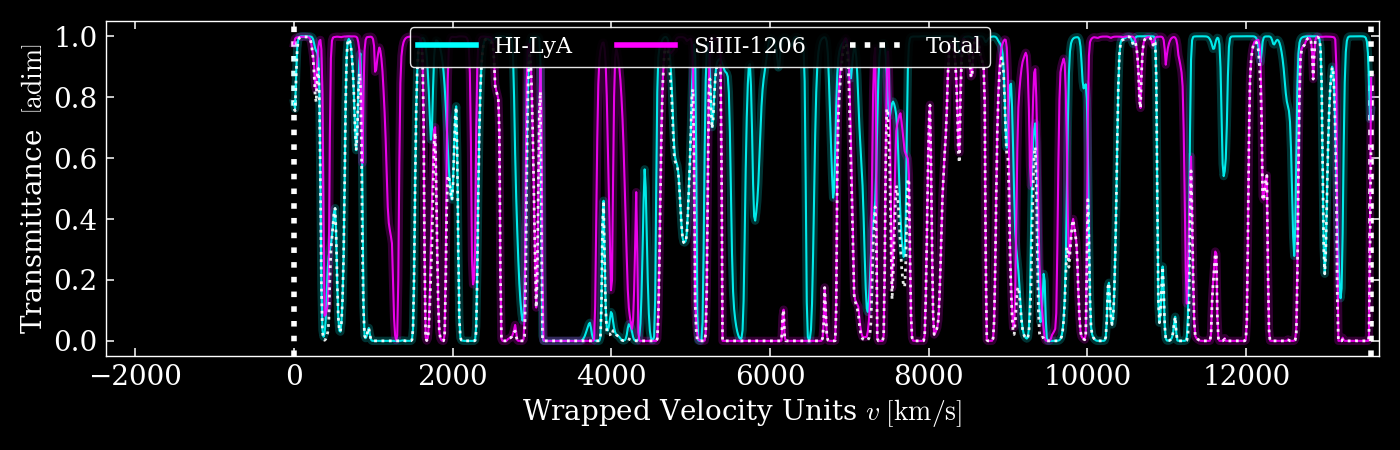

In [11]:
# --------------------------------------------- Wrapped Velocity Units --------------------------------------------- #
fig, ax = plt.subplots(1, 1, figsize=(14, 4.5), sharex=True, sharey=True, facecolor="black")
ax.set_facecolor("black")

kk = 0
handles = []
for ii, key_species in enumerate(line_bundle.species_keys):
    color = colors[key_species]
    for jj, line in enumerate(line_bundle.lines_for_species(key_species)):
        ls = linestyles[jj]
        
        ax.plot(velocities_kms, jnp.exp(-optical_depth_wrapped[kk, ii_skewer]), color=color, lw=6, ls=ls, alpha=0.2, zorder=2)
        ax.plot(velocities_kms, jnp.exp(-optical_depth_wrapped[kk, ii_skewer]), color=color, lw=1.5, ls=ls, alpha=0.9, zorder=3)
        
        handles.append(Line2D([0], [0], color=color, lw=4, ls=ls, label=line_bundle.lines[kk].id))
        kk += 1
        
ax.plot(velocities_kms, jnp.prod(jnp.exp(-optical_depth_wrapped[:, ii_skewer]), axis=0), color='white', lw=2.0, ls=':', alpha=0.9, zorder=5)
handles.append(Line2D([0], [0], color='white', lw=4, ls=':', label='Total'))
        
ax.set_xlim([v_min-100, v_max+100])
ax.set_ylim([-0.05, 1.05])

ax.axvline(0, color='white', lw=4, ls=':', zorder=1)
ax.axvline(phys.c_kms*jnp.log(a_dagger / a_em), color='white', lw=4, ls=':', zorder=2)

leg = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncols=min(len(handles), 7),
    frameon=True, fontsize=16, handlelength=2.6, facecolor="black", edgecolor="white", framealpha=0.9,
)
for text in leg.get_texts():
    text.set_color("white")
        
ax.tick_params(axis="both", which="major", labelsize=20, colors="white", length=6, width=1.1)
for side in ["top", "right", "bottom", "left"]:
    ax.spines[side].set_color("white")
    ax.spines[side].set_linewidth(1.0)
    
ax.set_ylabel(r"Transmittance $\; \left[\mathrm{adim}\right]$", fontsize=20, color="white")
ax.set_xlabel(r"Wrapped Velocity Units $v \; \left[\mathrm{km}/\mathrm{s}\right]$", fontsize=20, color="white")

fig.tight_layout()
plt.show()

# Overflux

In [12]:
overflux = sjx.optical_depth.overflux.DeltaFieldBuilder(optical_depth_wrapped).build()

2026-06-17 11:18:43,842 - INFO - Initialized DeltaFieldBuilder with 2 lines, N_samples=9, N_points=1024.
2026-06-17 11:18:43,843 - INFO - Starting build().
2026-06-17 11:18:44,020 - INFO - Finished build(): N_samples=9, subset_keys=3, composite_keys=1.


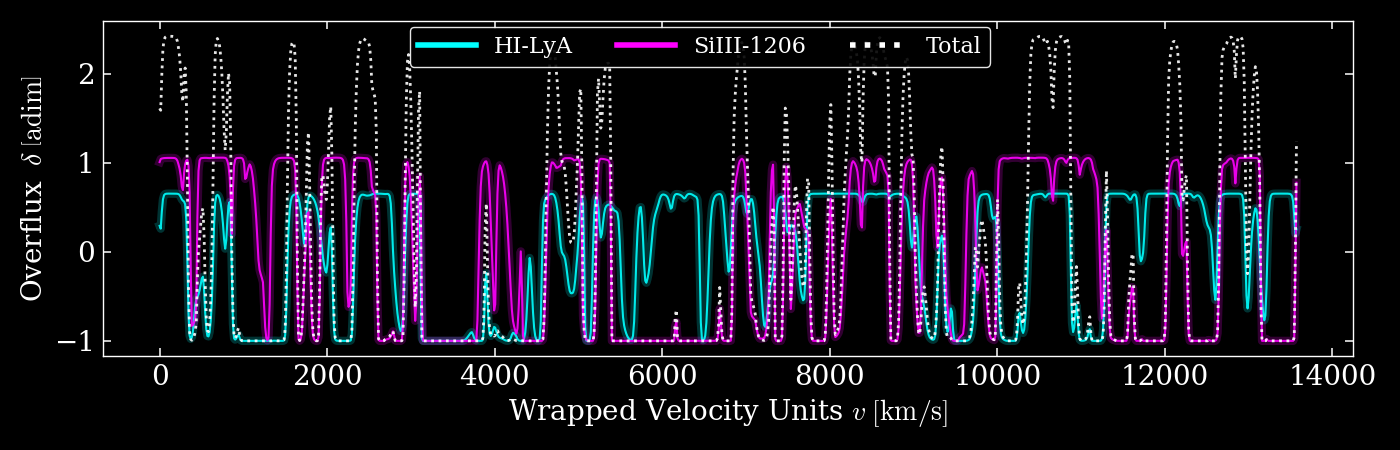

In [13]:
# --------------------------------------------- Wrapped Velocity Units --------------------------------------------- #
fig, ax = plt.subplots(1, 1, figsize=(14, 4.5), sharex=True, sharey=True, facecolor="black")
ax.set_facecolor("black")

kk = 0
handles = []
for ii, key_species in enumerate(line_bundle.species_keys):
    color = colors[key_species]
    for jj, line in enumerate(line_bundle.lines_for_species(key_species)):
        ls = linestyles[jj]
        
        _key = str(kk+1)
        
        ax.plot(velocities_kms, overflux.delta_terms[_key][ii_skewer], color=color, lw=6, ls=ls, alpha=0.2, zorder=2)
        ax.plot(velocities_kms, overflux.delta_terms[_key][ii_skewer], color=color, lw=1.5, ls=ls, alpha=0.9, zorder=3)
        
        handles.append(Line2D([0], [0], color=color, lw=4, ls=ls, label=line_bundle.lines[kk].id))
        kk += 1
        
ax.plot(velocities_kms, overflux.total[ii_skewer], color='white', lw=2.0, ls=':', alpha=0.9, zorder=5)
handles.append(Line2D([0], [0], color='white', lw=4, ls=':', label='Total'))

leg = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncols=min(len(handles), 7),
    frameon=True, fontsize=16, handlelength=2.6, facecolor="black", edgecolor="white", framealpha=0.9,
)
for text in leg.get_texts():
    text.set_color("white")
        
ax.tick_params(axis="both", which="major", labelsize=20, colors="white", length=6, width=1.1)
for side in ["top", "right", "bottom", "left"]:
    ax.spines[side].set_color("white")
    ax.spines[side].set_linewidth(1.0)
    
ax.set_ylabel(r"Overflux $\; \delta \; \left[\mathrm{adim}\right]$", fontsize=20, color="white")
ax.set_xlabel(r"Wrapped Velocity Units $v \; \left[\mathrm{km}/\mathrm{s}\right]$", fontsize=20, color="white")

fig.tight_layout()
plt.show()

# Summary stats

In [14]:
delta_v_list = list(np.array(line_bundle.delta_v))
velocity_domain = np.max(tau.velocities_kms) - np.min(tau.velocities_kms)
stats = sjx.summary_stats.P1D_xi1D.OverfluxStatistics1D(overflux, dv)
ordered_pairs = stats.ordered_pairs

In [15]:
stats.compute_p1d()

Pk_total_from_terms = stats.Pk_total_from_terms

Pk_total_per_sample = stats.Pk_total_per_sample
Pk_total = stats.Pk_total

Pk_pair_per_sample = stats.Pk_pair_per_sample
Pk_pair = stats.Pk_pair

k = stats.k

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:633: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


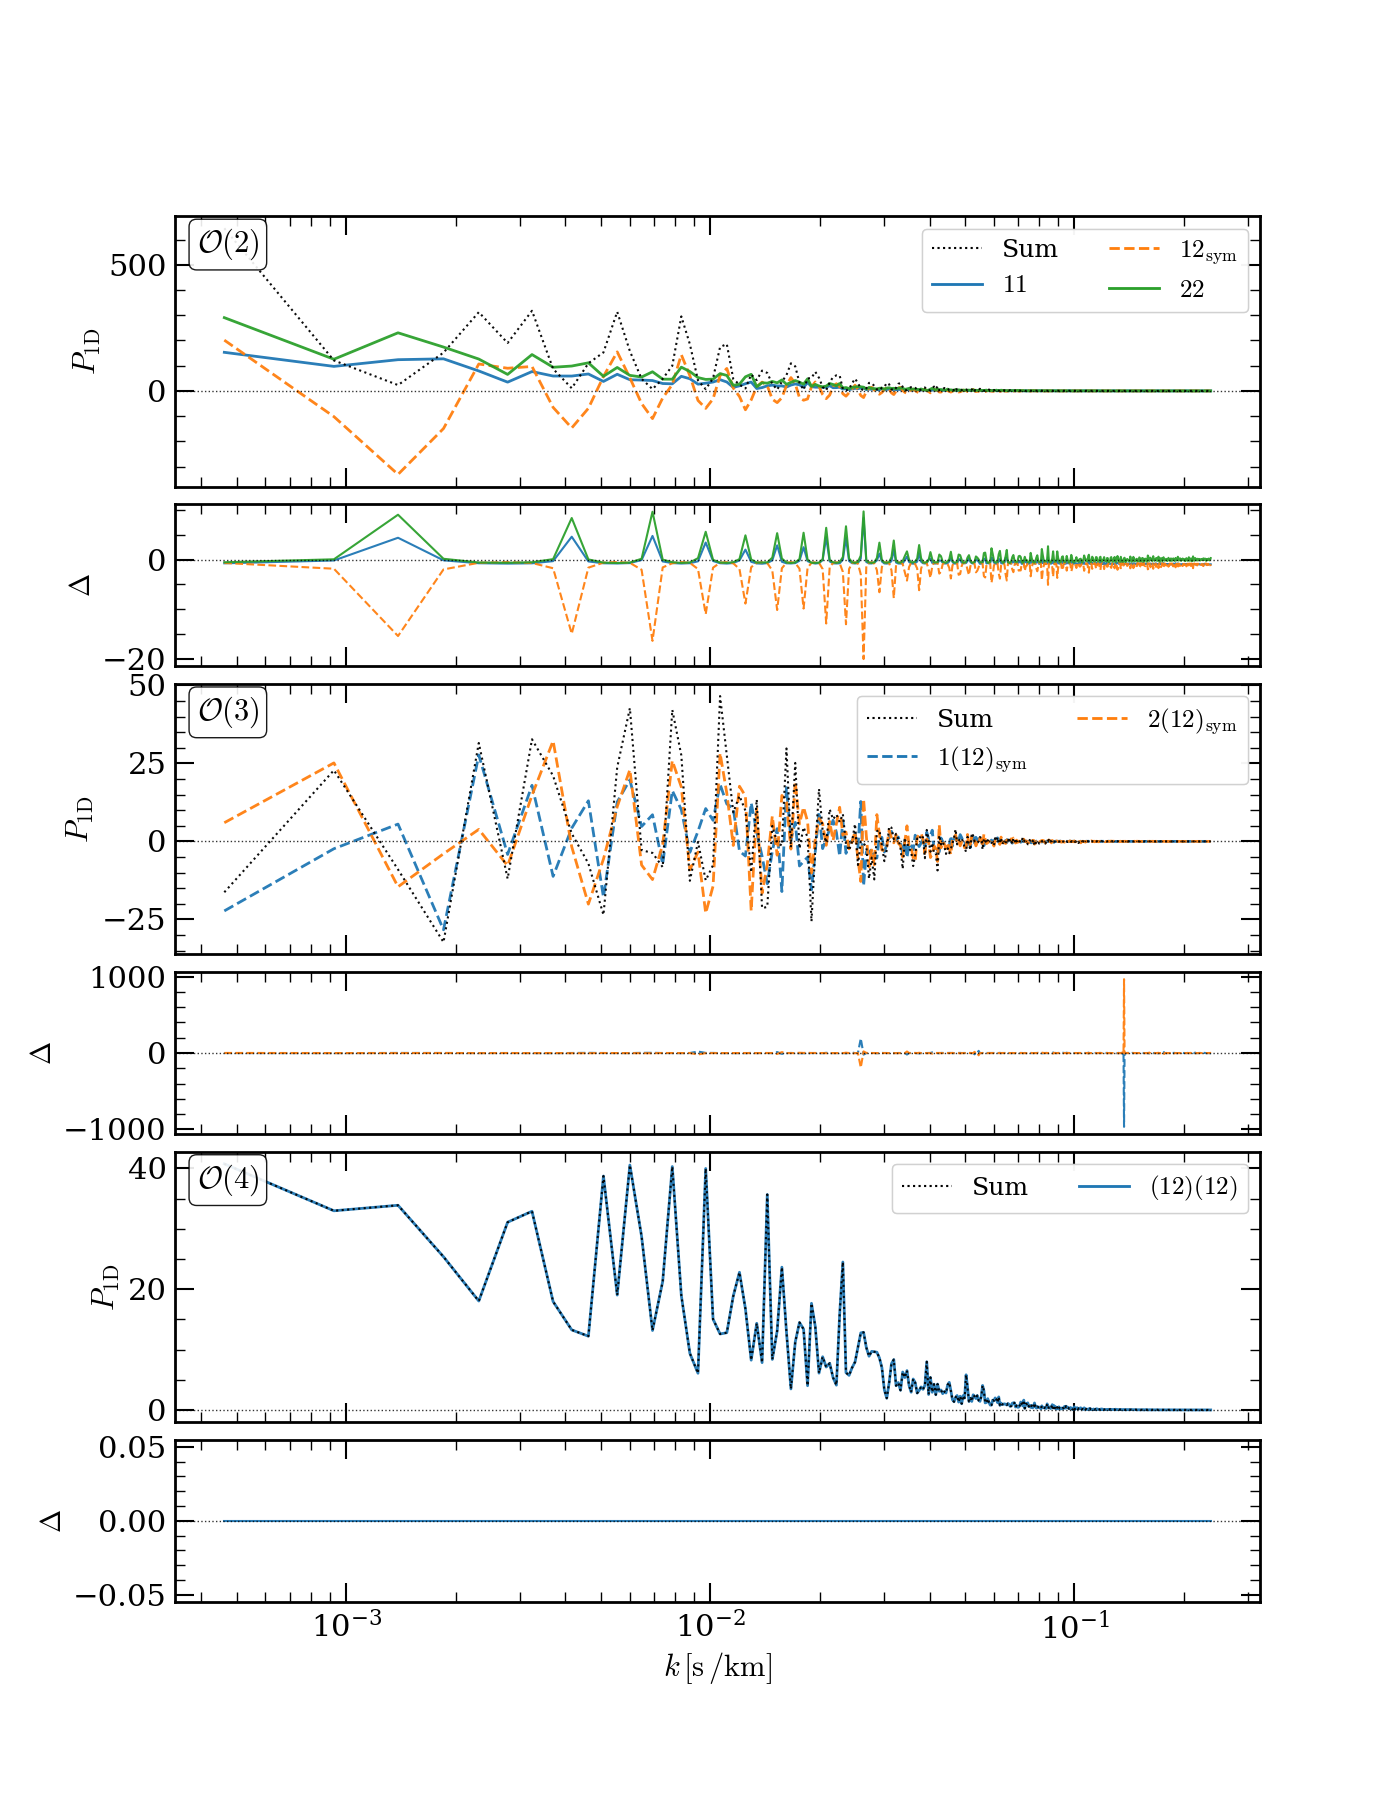

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:784: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


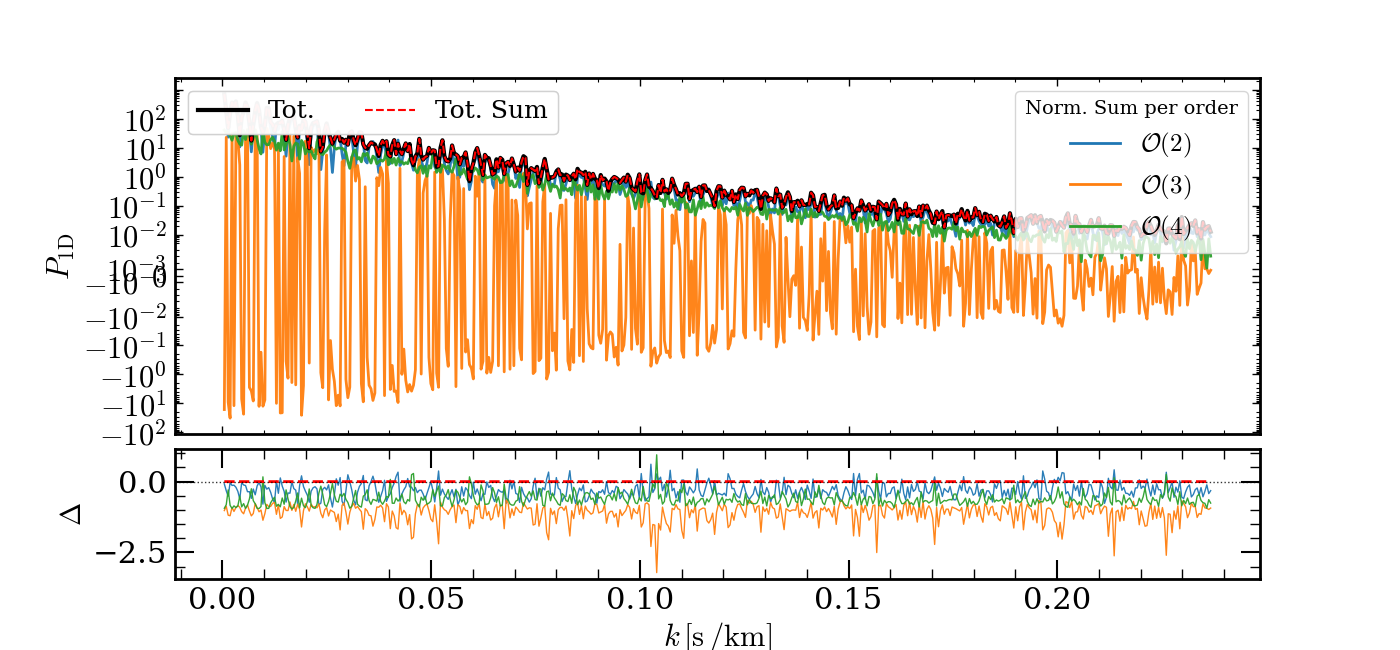

In [16]:
fig, axes, axes_res, order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_by_order(
    ordered_pairs=ordered_pairs, Pk_pair=Pk_pair, k=k, delta_v_list=delta_v_list, L_box=velocity_domain, Npix=tau.N_v,
    tolerance_threshold=1e-6, use_log_x=True, # xlim=(2.0, 600),
    residual_mode="sum", show_harmonics=False, use_symlog_main=False, use_symlog_residual=False,
    symlog_linscale=1.0, symlog_label_minor=False, symlog_sci_cutoff=1e-2, legend_ncol_terms=2,
    xlabel=r"$k\,[{\rm s\,/km}]$", ylabel=r"$P_{\rm 1D}$", residual_ylabel=r"$\Delta$",
)

fig, (ax, ax_res), order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_total_recovery(
    Pk_total=Pk_total, Pk_total_from_terms=Pk_total_from_terms, Pk_pair=Pk_pair, k=k, delta_v_list=delta_v_list, L_box=velocity_domain, Npix=tau.N_v,
    ordered_pairs=ordered_pairs, show_harmonics=False, show_order_sums=True, show_order_sum_residuals=True,
    use_symlog_main=True, use_symlog_residual=False, xlabel=r"$k\,[{\rm s\,/km}]$"
)

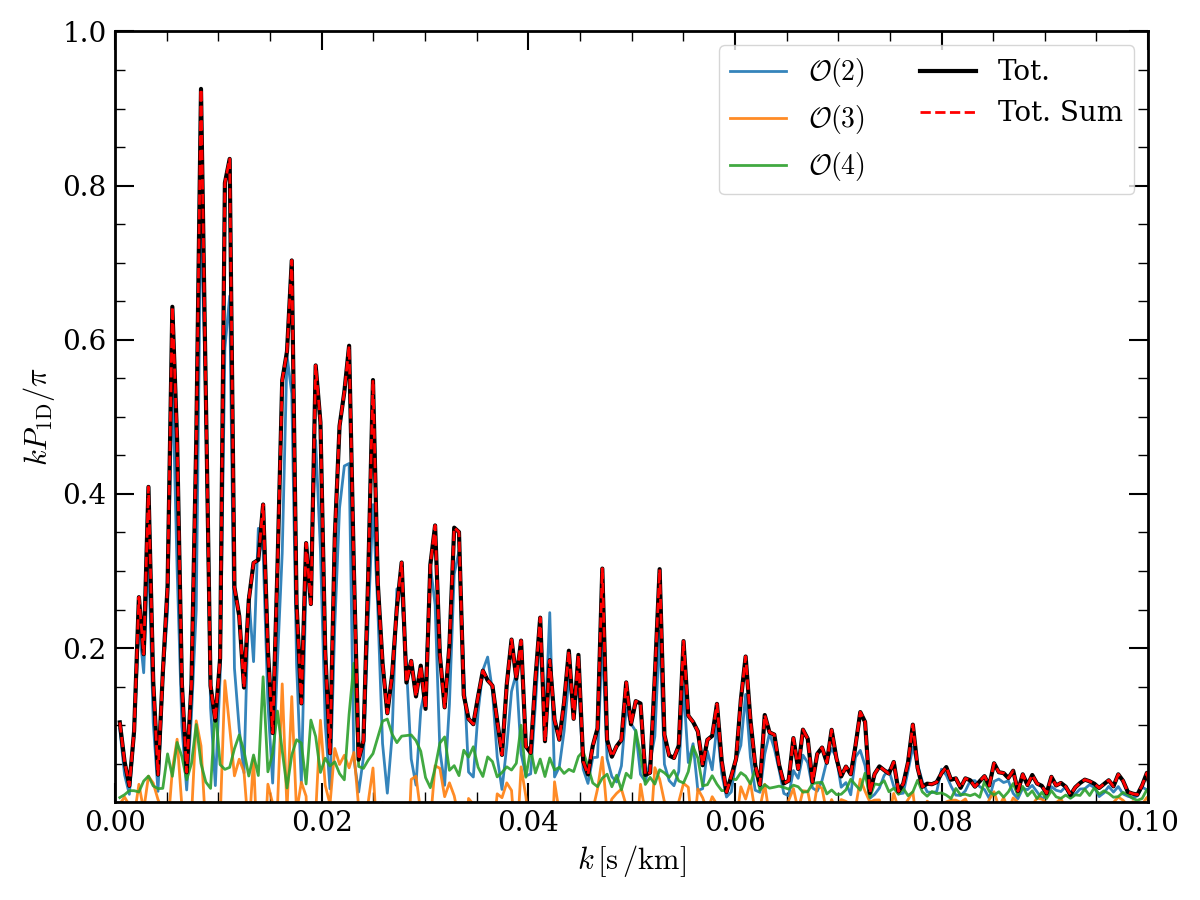

In [17]:
# ===============================================================
# Build order sums from Pk_pair

ordered_pairs = list(Pk_pair.keys()) if ordered_pairs is None else ordered_pairs
order_sum_dict = {}
for pair in ordered_pairs:
    A, B = pair
    order = len(A) + len(B)
    if order not in order_sum_dict:
        order_sum_dict[order] = np.zeros_like(Pk_pair[pair], dtype=float)
    order_sum_dict[order] += Pk_pair[pair].real
orders = sorted(order_sum_dict.keys())

# ===============================================================
# Plot P1D

cmap = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(12, 9))
for i, order in enumerate(orders):
    y_order = order_sum_dict[order][1:] * k[1:] / np.pi
    ax.plot(k[1:], y_order, lw=2.0, color=cmap(i % 10), alpha=0.9, label=rf"$\mathcal{{O}}({order})$")

# Total
ax.plot(k[1:], Pk_total.real[1:] * k[1:] / np.pi, lw=3.0, color="k", label=r"Tot.")

# Total recovered from terms
ax.plot(k[1:], Pk_total_from_terms.real[1:] * k[1:] / np.pi, lw=2.0, color="red", ls="--", label=r"Tot. Sum")

# ax.set_yscale("log")

ax.set_xlabel(r"$k\,[{\rm s\,/km}]$", fontsize=22)
ax.set_ylabel(r"$k P_{\rm 1D} / \pi$", fontsize=22)

ax.set_xlim([0.0, 0.1])
ax.set_ylim([1e-4, 1e0])

ax.tick_params(axis="both", labelsize=20)
ax.legend(fontsize=20, ncol=2)

plt.tight_layout()
plt.show()

In [18]:
stats.compute_xi1d()

xi_total_from_terms = stats.xi_total_from_terms

xi_total_per_sample = stats.xi_total_per_sample
xi_total = stats.xi_total

xi_pair_per_sample = stats.xi_pair_per_sample
xi_pair = stats.xi_pair

lags = stats.lags

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:978: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


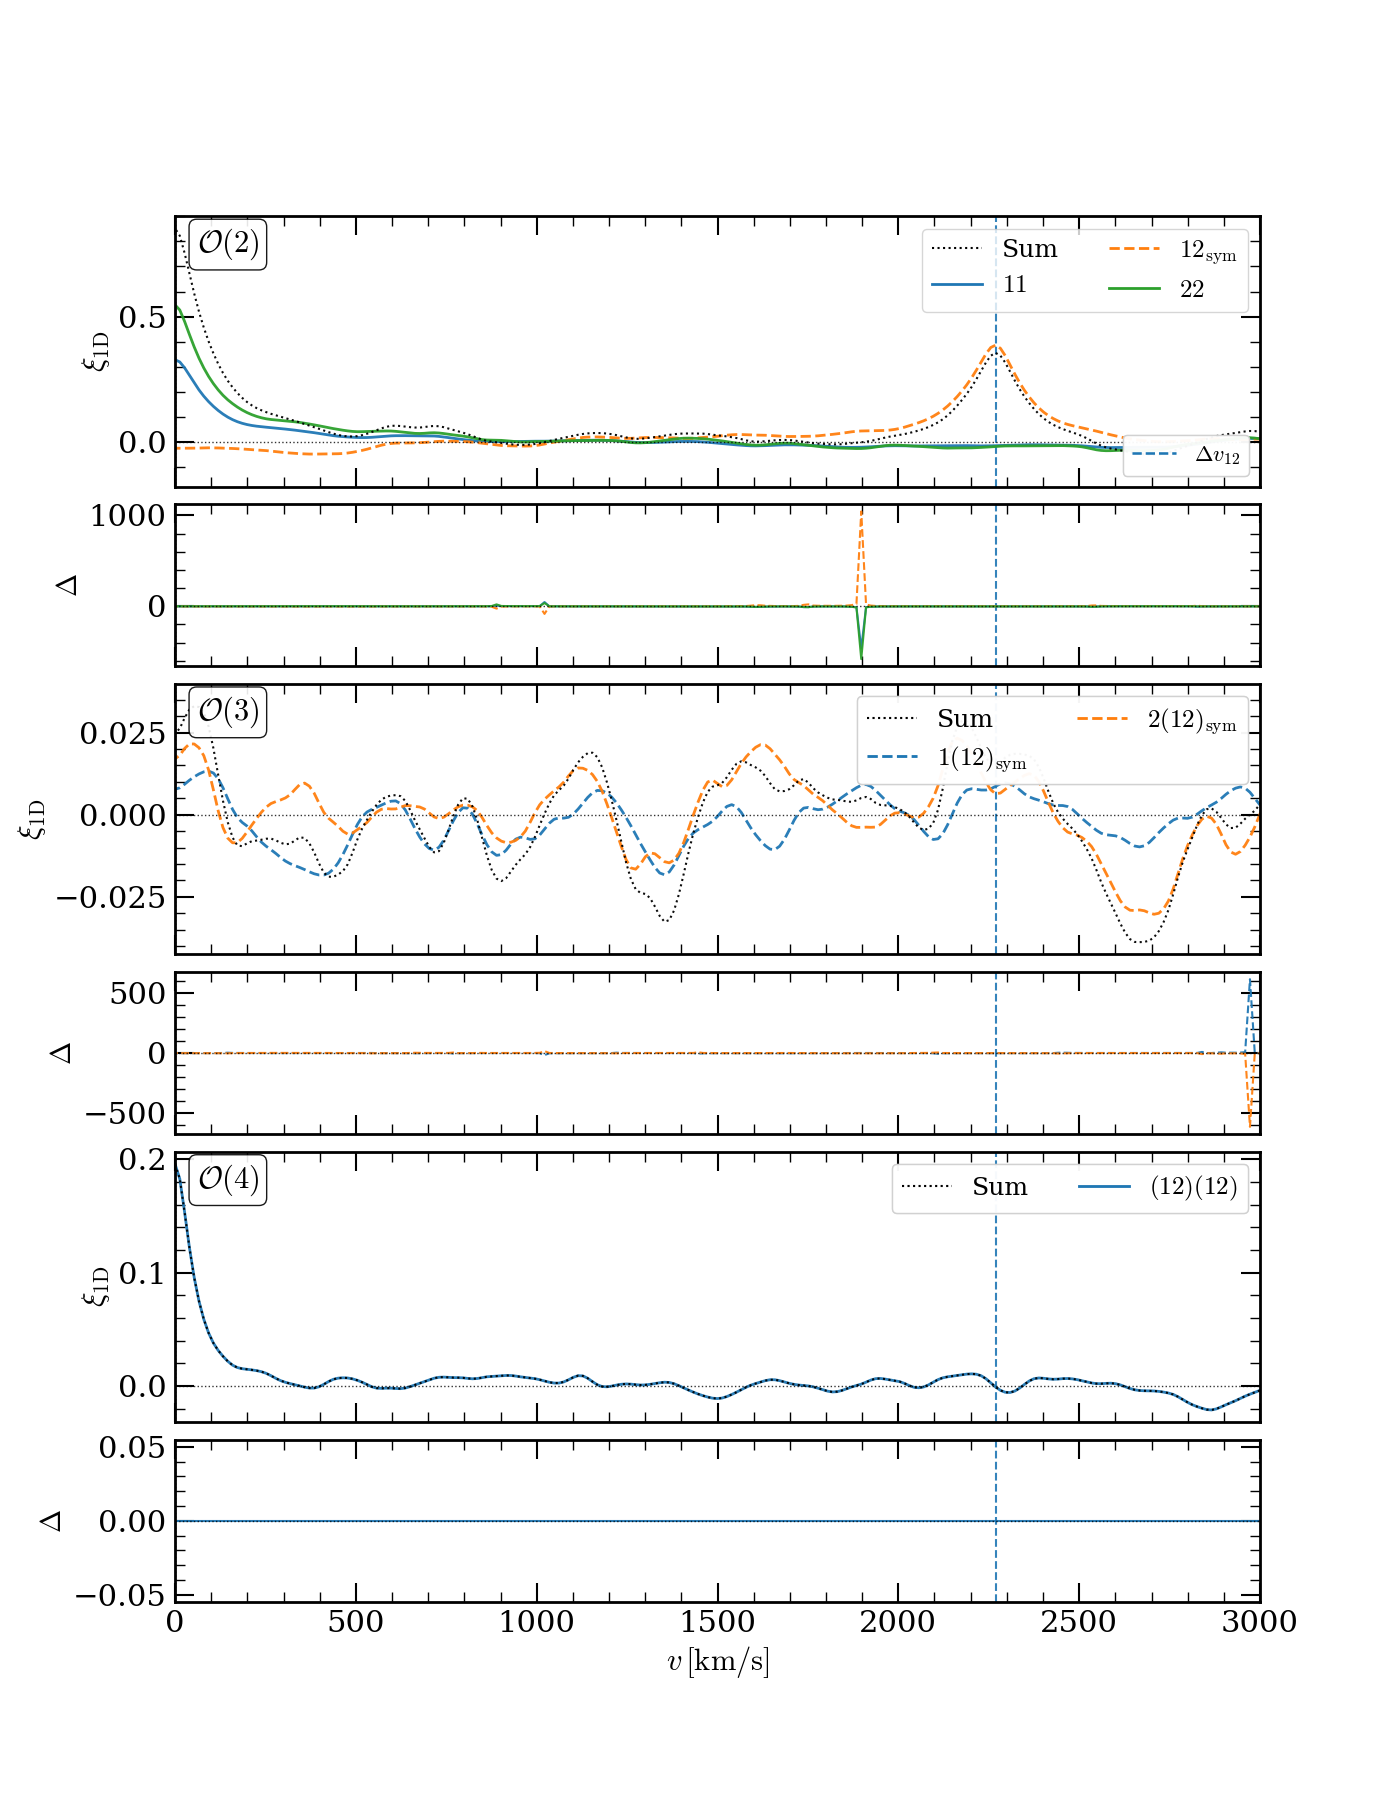

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:1137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


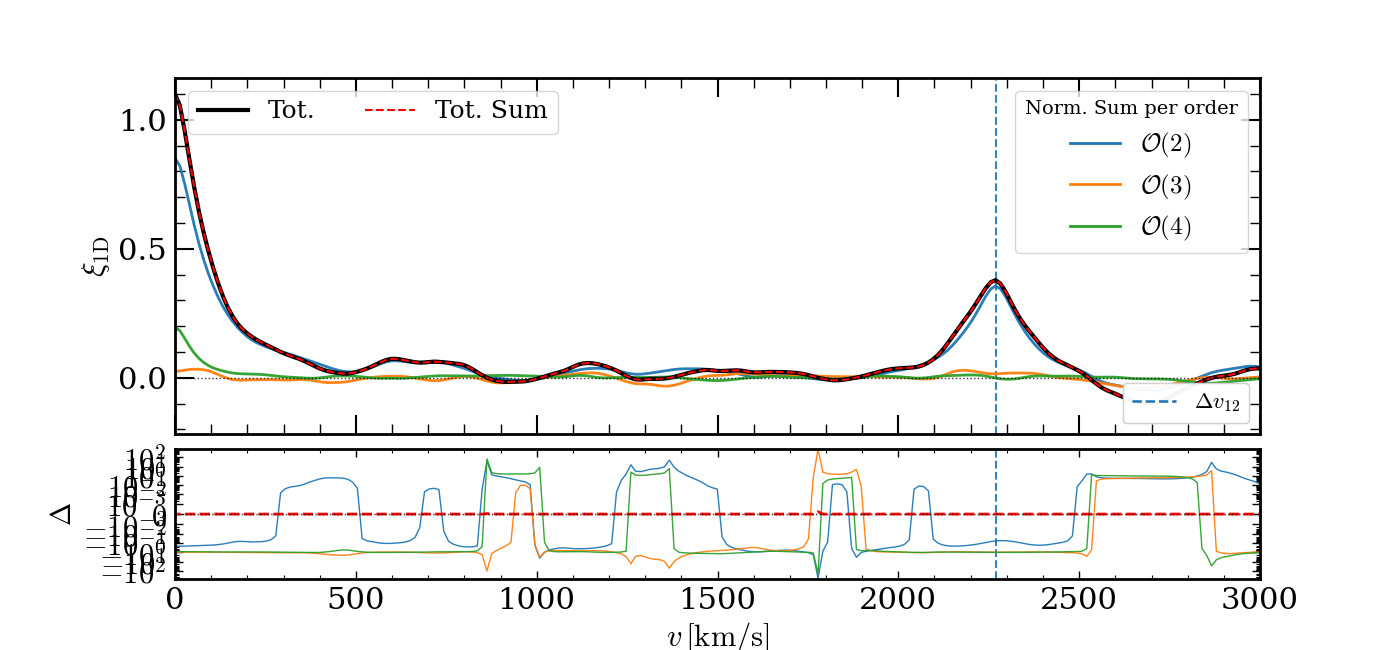

In [19]:
fig, axes, axes_res, xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_by_order(
    ordered_pairs=ordered_pairs, xi_pair=xi_pair, lags=lags, delta_v_list=delta_v_list, L_box=velocity_domain,
    tolerance_threshold=1e-6, residual_mode="sum", show_delta_v_diff_lines=True, use_symlog_main=False,
    use_symlog_residual=False, symlog_linscale=1.0, symlog_base=10, symlog_label_minor=False, symlog_sci_cutoff=1e-2,
    show_order_badge=True, legend_ncol_terms=2, xlabel=r"$v\,\left[{\rm km / s}\right]$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
    xlim=(-0.0, 3000), # xlim=(-0.0, v_max/2)
)

fig, (ax, ax_res), xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_total_recovery(
    xi_total=xi_total, xi_total_from_terms=xi_total_from_terms, xi_pair=xi_pair, lags=lags, delta_v_list=delta_v_list, L_box=velocity_domain, ordered_pairs=ordered_pairs,
    show_order_sums=True, show_order_sum_residuals=True, show_delta_v_diff_lines=True, annotate_half_line=False,
    half_line_text=r"$L_\mathrm{box}/2$", use_symlog_main=False, use_symlog_residual=True, main_symlog_linthresh=None,
    symlog_linscale=1.0, symlog_base=10, symlog_sci_cutoff=1e-2, xlabel=r"$v\,\left[{\rm km / s}\right]$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
    xlim=(-0.0, 3000), # xlim=(-0.0, v_max/2)
)